# 📊 NGÀY 1: KHÁM PHÁ ĐỊNH LƯỢNG (QUANT EDA) & KIỂM CHỨNG 5 STYLIZED FACTS
### Đề tài: *Stock Movement Prediction & ML-Based Trading Strategy Backtesting*
**Mã:** HPG (HOSE) | **Giai đoạn cấu hình:** 2016–2026 | **Tần suất:** ngày

Notebook khảo sát nghiệm đơn vị, phân phối lợi suất, tự tương quan và biến động, các proxy biên độ và nhãn nghiên cứu, cùng drawdown. Các kiểm định mô tả mẫu quan sát, không chứng minh quy luật luôn đúng hoặc khả năng tạo alpha.

---
## 🛠️ Bước 0: Thiết lập Môi trường & Khai báo Thư viện
### Giải thích:
* Chúng ta cần các thư viện xử lý số liệu mạnh nhất: `pandas`, `numpy`, `scipy.stats`.
* Thư viện chuyên dụng kinh tế lượng: `statsmodels` (chứa các phép kiểm định ADF Test, Ljung-Box Test, biểu đồ ACF).
* Thiết lập giao diện đồ họa chuẩn học thuật (`seaborn-v0_8-whitegrid`, font size rõ ràng, độ phân giải cao).


In [1]:
import sys
from pathlib import Path

# Thêm thư mục gốc vào đường dẫn hệ thống để có thể import từ src/
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

# Cấu hình thẩm mỹ đồ thị
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print(f"✅ Môi trường đã sẵn sàng! Thư mục dự án: {project_root}")


✅ Môi trường đã sẵn sàng! Thư mục dự án: G:\AI_CODE4LIFE\My_Project\Machine_Learning\stock-ml-backtesting


---
## 📂 Bước 1: Nạp Dữ liệu 10 Năm HPG & Kiểm tra Tính Toàn vẹn (Sanity Check)

File parquet được tạo bởi `src/data_loader.py`. Khi Yahoo cung cấp cả Close và Adj Close, pipeline nhân Open/High/Low với tỷ số Adj Close/Close và dùng Adj Close; volume được giữ nguyên theo nhà cung cấp. Corporate actions được phản ánh qua hệ số của nhà cung cấp, không được xử lý riêng hay kiểm chứng ở đây. Nếu thiếu Adj Close pipeline dùng OHLC trả về trực tiếp, không xác minh được đã điều chỉnh hay chưa. Pipeline chỉ lưu OHLCV, không lưu giá gốc, hệ số hay metadata, nên không thể xác minh nhánh nào đã tạo parquet hiện tại hoặc tính nhất quán điều chỉnh volume từ riêng file này. Pipeline cũng sửa high/low theo cực trị OHLC. Cần đối chiếu nguồn và corporate actions trước khi sử dụng giao dịch thực tế.

In [2]:
# Đọc file cấu hình config.yaml
config_path = project_root / "configs" / "config.yaml"
with open(config_path, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Lưu biểu đồ của notebook 01 vào thư mục EDA riêng.
figures_dir = project_root / config["eda"]["figures_dir"]
figures_dir.mkdir(parents=True, exist_ok=True)

# Đường dẫn file Parquet đã kéo về ở Bước Data Ingestion
raw_parquet_path = project_root / config["data"]["raw_parquet_path"]
df_raw = pd.read_parquet(raw_parquet_path)

print(f"📊 Tổng số phiên giao dịch 10 năm: {len(df_raw)} phiên")
print(f"⏳ Khung thời gian thực tế: từ {df_raw.index.min().strftime('%d/%m/%Y')} đến {df_raw.index.max().strftime('%d/%m/%Y')}")
print("\n5 phiên đầu tiên (Năm 2016):")
display(df_raw.head())
print("\n5 phiên gần nhất (Năm 2026):")
display(df_raw.tail())


📊 Tổng số phiên giao dịch 10 năm: 2639 phiên
⏳ Khung thời gian thực tế: từ 04/01/2016 đến 30/10/2026

5 phiên đầu tiên (Năm 2016):


Price,open,high,low,close,volume
date,,,,,
2016-01-04,2570.426883,2588.093129,2543.927734,2543.927734,4148213
2016-01-05,2535.094737,2552.760984,2517.428711,2517.428711,6447558
2016-01-06,2517.428600,2561.593994,2517.428600,2561.593994,6754883
2016-01-07,2526.261718,2535.094842,2482.096319,2490.929443,10563368
2016-01-08,2446.763672,2482.095941,2429.097427,2446.763672,8862778



5 phiên gần nhất (Năm 2026):


Price,open,high,low,close,volume
date,,,,,
2026-10-26,20950.0,21100.0,20900.0,20900.0,10478100
2026-10-27,20900.0,21200.0,20850.0,21000.0,9524500
2026-10-28,21100.0,21150.0,20750.0,20750.0,13204500
2026-10-29,20800.0,21600.0,20750.0,21200.0,36410800
2026-10-30,21250.0,21500.0,21000.0,21000.0,24773000


---
## 📐 Bước 2: Tính toán Chuỗi Lợi suất (Returns) & Biến Mục tiêu (Targets)

Simple return $R_t=P_t/P_{t-1}-1$; log return $r_t=\ln(P_t/P_{t-1})$. Log return cộng theo thời gian: $\sum_{t=1}^{T}r_t=\ln(P_T/P_0)$; simple return tổng là $\prod_t(1+R_t)-1$. Ví dụ 100 tăng 10% thành 110 rồi giảm 10% còn 99: simple return tổng là -1%, log return tổng là $\ln(99/100)$, không phải 0.

* `target_direction`: 1 nếu log return close(t) → close(t+1) dương, 0 nếu không; nhãn cuối không có tương lai là missing.
* `target_return_above_cost_proxy`: 1 nếu log return tiếp theo vượt `round_trip_cost` trong config. Đây là ngưỡng nghiên cứu thống kê trên log return, dùng chi phí tỷ lệ như proxy, không phải PnL ròng. Chi phí thực tế phụ thuộc phí, thuế, slippage, giá và thời điểm thực thi, quy tắc nắm giữ.

Các feature ở t chỉ có sau khi phiên t kết thúc; nhãn RQ1 dùng close(t) → close(t+1). Backtest cần xác định giá thực thi riêng, ví dụ Open(t+1), và quy tắc nắm giữ; không mặc định có thể giao dịch ở close(t). Horizon ở đây vẫn là một phiên. Rolling statistics chỉ dùng dữ liệu đến t.

In [3]:
df = df_raw.sort_index().copy()
assert df.index.is_unique and (df["close"] > 0).all(), "Index phải duy nhất và close dương"
# Lợi suất chỉ dùng close hiện tại và quá khứ.
df["simple_return"] = df["close"].pct_change()
df["log_return"] = np.log(df["close"] / df["close"].shift(1))
df["next_log_return"] = df["log_return"].shift(-1)

costs = config["market_microstructure"]
round_trip_cost = costs["round_trip_cost"]
component_cost = costs["commission_buy"] + costs["commission_sell"] + costs["tax_sell"] + 2 * costs["slippage"]
print(f"Ngưỡng proxy cấu hình: {round_trip_cost:.2%}; tổng thành phần với slippage mỗi chiều: {component_cost:.2%}.")
if not np.isclose(round_trip_cost, component_cost):
    print("⚠️ Cấu hình bất nhất: cần xác nhận chính sách phí; phân tích giữ ngưỡng cấu hình hiện tại.")
valid_future = df["next_log_return"].notna()
df["target_direction"] = (df["next_log_return"] > 0).where(valid_future).astype("Int64")
df["target_return_above_cost_proxy"] = (df["next_log_return"] > round_trip_cost).where(valid_future).astype("Int64")
assert pd.isna(df["target_direction"].iloc[-1]) and pd.isna(df["target_return_above_cost_proxy"].iloc[-1])
df = df.dropna(subset=["simple_return", "log_return", "next_log_return", "target_direction", "target_return_above_cost_proxy"]).copy()
print(f"Số mẫu có cả return hiện tại và nhãn tương lai: {len(df)} phiên.")
display(df[["close", "simple_return", "log_return", "next_log_return", "target_direction", "target_return_above_cost_proxy"]].head())

Ngưỡng proxy cấu hình: 0.45%; tổng thành phần với slippage mỗi chiều: 0.50%.
⚠️ Cấu hình bất nhất: cần xác nhận chính sách phí; phân tích giữ ngưỡng cấu hình hiện tại.
Số mẫu có cả return hiện tại và nhãn tương lai: 2637 phiên.


Price,close,simple_return,log_return,next_log_return,target_direction,target_return_above_cost_proxy
date,,,,,,
2016-01-05,2517.428711,-0.010417,-0.010471,0.017392,1,1
2016-01-06,2561.593994,0.017544,0.017392,-0.027974,0,0
2016-01-07,2490.929443,-0.027586,-0.027974,-0.017890,0,0
2016-01-08,2446.763672,-0.017731,-0.017890,0.000000,0,0
2016-01-11,2446.763672,0.000000,0.000000,0.010772,1,1


---
## 📉 Bước 3: Phân tích Đồ thị Giá & "Hồ ngập lụt" Drawdown Profile (10 Năm HPG)

### Cách đọc biểu đồ Underwater Drawdown:
* **Công thức Drawdown tại ngày $t$:**
  $$DD_t = \frac{P_t - \max_{\tau \le t}(P_\tau)}{\max_{\tau \le t}(P_\tau)}$$
* $DD_t$ luôn $\le 0$. Khi tài sản đang ở đỉnh cao nhất lịch sử (All-Time High), $DD_t = 0\%$.
* Khi thị trường sập, đồ thị sẽ chìm sâu xuống dưới mặt nước ("Underwater").
* **Maximum Drawdown (MDD):** Đáy sâu nhất của đồ thị này trong 10 năm. Đây là mức giảm lớn nhất từ đỉnh trước đó trong khoảng mẫu giá quan sát, không phải drawdown của một chiến lược.

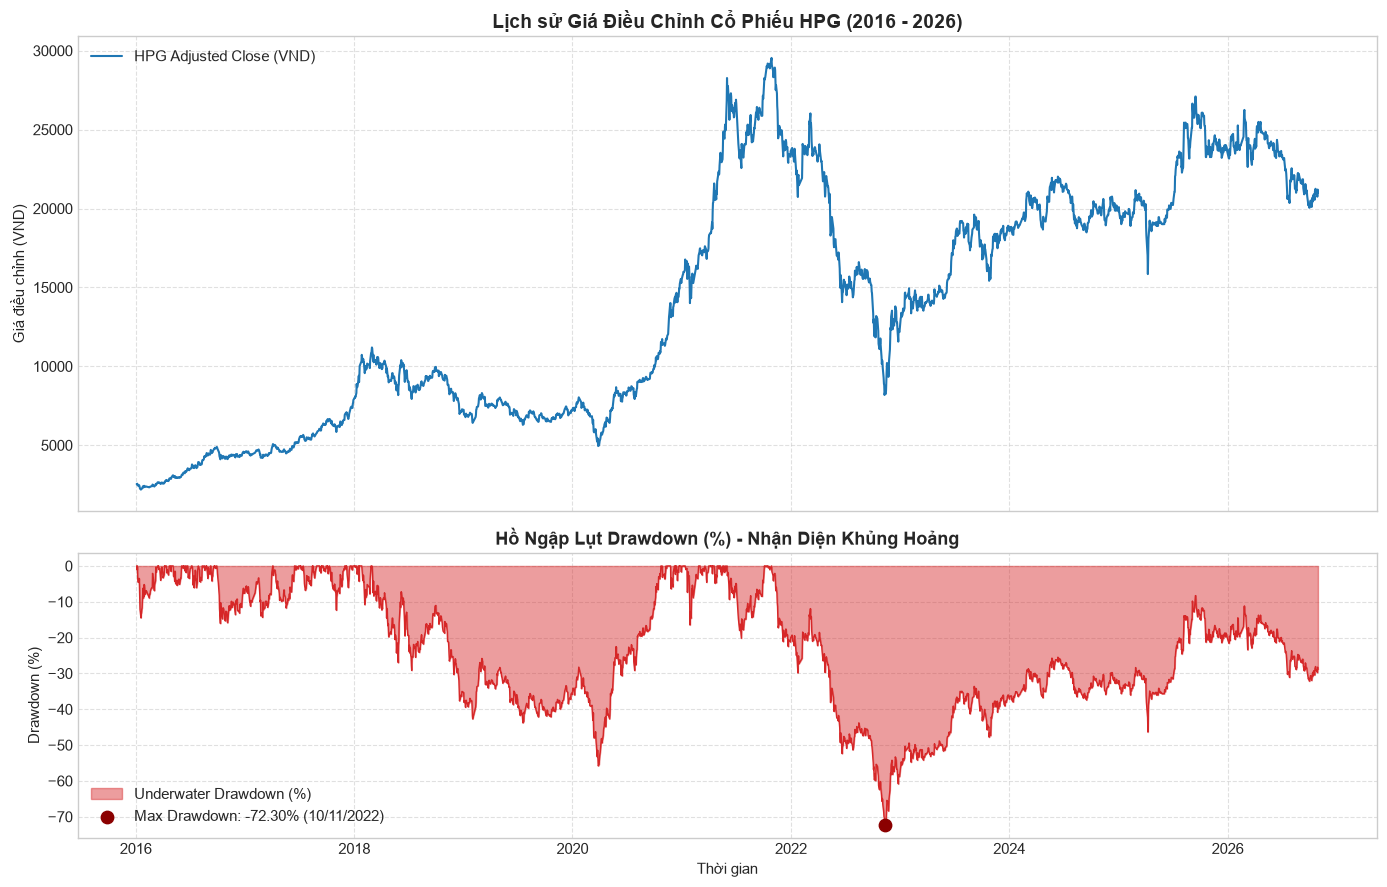

⚠️ Maximum Drawdown (MDD) của HPG: -72.30% rơi vào ngày 10/11/2022.
Drawdown tính trên toàn bộ close trong parquet, từ đỉnh tích lũy trong mẫu; không bao gồm chi phí giao dịch.


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})

# Đồ thị 1: Giá đóng cửa điều chỉnh 10 năm của HPG
axes[0].plot(df_raw.index, df_raw["close"], color="#1f77b4", linewidth=1.5, label="HPG Adjusted Close (VND)")
axes[0].set_title("Lịch sử Giá Điều Chỉnh Cổ Phiếu HPG (2016 - 2026)", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Giá điều chỉnh (VND)")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Đồ thị 2: Underwater Drawdown
rolling_max = df_raw["close"].cummax()
drawdown = (df_raw["close"] - rolling_max) / rolling_max * 100
mdd = drawdown.min()
mdd_date = drawdown.idxmin()

axes[1].fill_between(df_raw.index, drawdown, 0, color="#d62728", alpha=0.45, label="Underwater Drawdown (%)")
axes[1].plot(df_raw.index, drawdown, color="#d62728", linewidth=1.0)
axes[1].scatter([mdd_date], [mdd], color="darkred", s=80, zorder=5, 
                label=f"Max Drawdown: {mdd:.2f}% ({mdd_date.strftime('%d/%m/%Y')})")
axes[1].set_title("Hồ Ngập Lụt Drawdown (%) - Nhận Diện Khủng Hoảng", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_xlabel("Thời gian")
axes[1].legend(loc="lower left")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
fig.savefig(figures_dir / "notebook_01_price_and_drawdown.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"⚠️ Maximum Drawdown (MDD) của HPG: {mdd:.2f}% rơi vào ngày {mdd_date.strftime('%d/%m/%Y')}.")
print("Drawdown tính trên toàn bộ close trong parquet, từ đỉnh tích lũy trong mẫu; không bao gồm chi phí giao dịch.")

---
## 🧪 Bước 4: Kiểm chứng [FACT 1] - Tính Dừng (Stationarity) & ADF Test

ADF kiểm định $H_0$: có nghiệm đơn vị, so với đối thuyết dừng quanh thành phần xác định theo đặc tả kiểm định. Ở mức 5%, p-value nhỏ hơn 0.05 cho bằng chứng bác bỏ $H_0$; nếu không thì chưa đủ bằng chứng bác bỏ. Bác bỏ không chứng minh tính dừng tuyệt đối, và kết quả phụ thuộc mẫu, độ trễ, đặc tả; log return không nhất thiết dừng trong mọi giai đoạn. Các đặc trưng và biến đổi cần được kiểm tra theo thời gian thay vì mặc định giá thô hay mọi chỉ báo đều phù hợp.

In [5]:
# Chạy ADF Test cho Giá đóng cửa thô
adf_close = adfuller(df["close"])
# Chạy ADF Test cho Chuỗi Log Return
adf_ret = adfuller(df["log_return"])

adf_results = pd.DataFrame({
    "Chuỗi dữ liệu": ["Giá đóng cửa (Close)", "Lợi suất Log (Log Return)"],
    "ADF Statistic": [f"{adf_close[0]:.4f}", f"{adf_ret[0]:.4f}"],
    "p-value": [f"{adf_close[1]:.4f}", f"{adf_ret[1]:.4e}"],
    "Số Lags sử dụng": [adf_close[2], adf_ret[2]],
    "Số quan sát": [adf_close[3], adf_ret[3]],
    "Ngưỡng 1%": [f"{adf_close[4]['1%']:.4f}", f"{adf_ret[4]['1%']:.4f}"],
    "Ngưỡng 5%": [f"{adf_close[4]['5%']:.4f}", f"{adf_ret[4]['5%']:.4f}"],
    "Kết luận Thống kê": [
        "Bác bỏ H0 nghiệm đơn vị" if result[1] < 0.05 else "Chưa đủ bằng chứng bác bỏ H0 nghiệm đơn vị"
        for result in (adf_close, adf_ret)
    ]
})
display(adf_results)
print("Diễn giải tại mức 5%; kết quả phụ thuộc mẫu và đặc tả ADF, không chứng minh tính dừng tuyệt đối.")

C:\Users\MYLAPT~1\AppData\Local\Temp\ipykernel_2888\1296270150.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_close = adfuller(df["close"])


C:\Users\MYLAPT~1\AppData\Local\Temp\ipykernel_2888\1296270150.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_ret = adfuller(df["log_return"])


,Chuỗi dữ liệu,ADF Statistic,p-value,Số Lags sử dụng,Số quan sát,Ngưỡng 1%,Ngưỡng 5%,Kết luận Thống kê
0,Giá đóng cửa (Close),-1.3913,0.5864,2,2634,-3.4328,-2.8626,Chưa đủ bằng chứng bác bỏ H0 nghiệm đơn vị
1,Lợi suất Log (Log Return),-50.0257,0.0000e+00,0,2636,-3.4328,-2.8626,Bác bỏ H0 nghiệm đơn vị


Diễn giải tại mức 5%; kết quả phụ thuộc mẫu và đặc tả ADF, không chứng minh tính dừng tuyệt đối.


---
## 🔔 Bước 5: Kiểm chứng [FACT 2] - Phân phối Đuôi béo (Fat Tails) & Kiểm định Normality

Mean và standard deviation mô tả log return ngày; skewness mô tả bất đối xứng mẫu, gần 0 không cho thấy lệch mạnh. Excess kurtosis so với Gaussian bằng 0; giá trị dương là dấu hiệu leptokurtic theo moment, không xác định tần suất từng biến cố. Jarque-Bera kiểm định giả thuyết Gaussian dựa trên skewness và kurtosis: bác bỏ không xác định một phân phối khác hay chứng minh riêng một sự kiện Black Swan. Đồ thị Q-Q và histogram bổ sung bằng chứng mô tả.

,Chỉ số thống kê,Giá trị,Ý nghĩa định lượng
0,Lợi suất trung bình ngày (Daily Mean),0.0804%,Trung bình log return theo phiên
1,Log return trung bình năm hóa,20.26%,Trung bình log return nhân số phiên/năm; không...
2,Độ biến động ngày (Daily Volatility),2.0725%,Độ lệch chuẩn log return ngày
3,Độ biến động hàng năm (Annualized Volatility),32.90%,Độ lệch chuẩn ngày nhân căn số phiên/năm
4,Độ lệch (Skewness),-0.0419,Độ bất đối xứng mẫu; giá trị gần 0 không cho t...
5,Độ nhọn đuôi béo (Excess Kurtosis),2.3064,Excess kurtosis mẫu so với Gaussian
6,Jarque-Bera Test Statistic,581.89,Thống kê kiểm định normality
7,Jarque-Bera p-value,4.4174e-127,Bác bỏ H0 Gaussian ở mức 5%


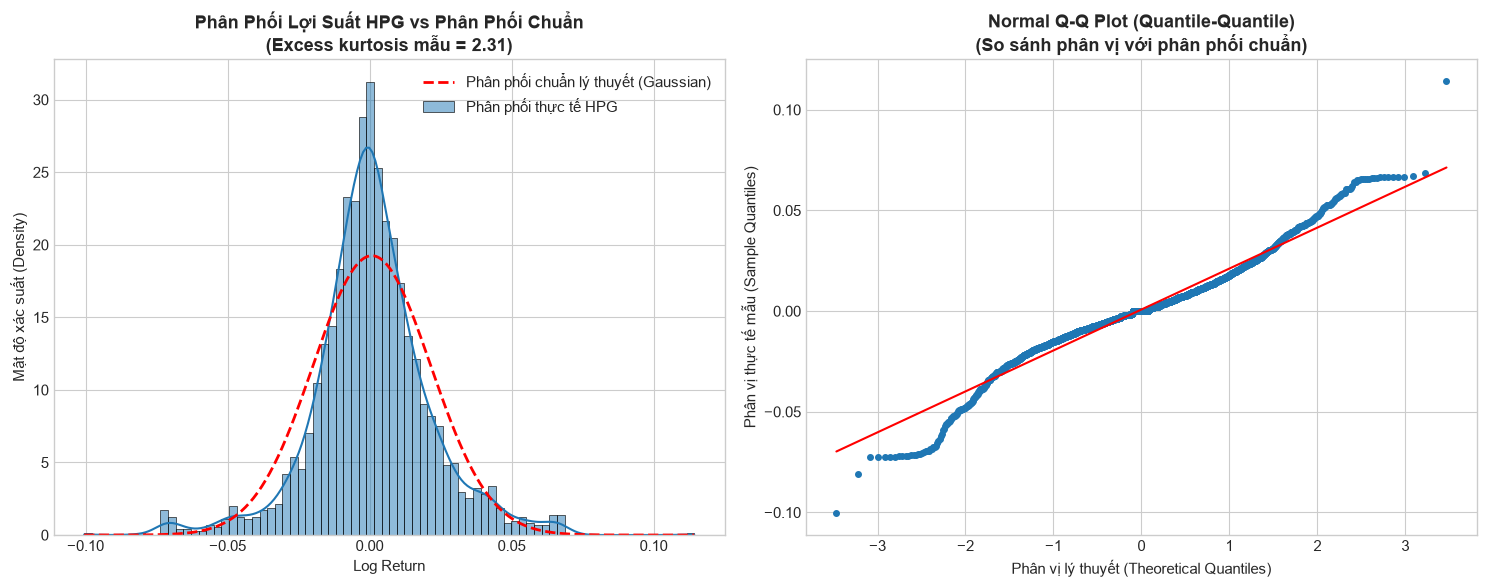

In [6]:
ret = df["log_return"]

mean_d = ret.mean()
trading_days = config["market_microstructure"]["trading_days_per_year"]
mean_ann = mean_d * trading_days # Log return trung bình năm hóa, không phải CAGR
vol_d = ret.std()
vol_ann = vol_d * np.sqrt(trading_days) # Quy tắc căn thời gian, giả định phụ thuộc thích hợp
skewness = ret.skew()
kurt = ret.kurtosis() # Pandas tự động tính Excess Kurtosis (so với 0 của Normal)
jb_stat, jb_pval = stats.jarque_bera(ret)

# Bảng tổng hợp thống kê
moments_df = pd.DataFrame({
    "Chỉ số thống kê": [
        "Lợi suất trung bình ngày (Daily Mean)",
        "Log return trung bình năm hóa",
        "Độ biến động ngày (Daily Volatility)",
        "Độ biến động hàng năm (Annualized Volatility)",
        "Độ lệch (Skewness)",
        "Độ nhọn đuôi béo (Excess Kurtosis)",
        "Jarque-Bera Test Statistic",
        "Jarque-Bera p-value"
    ],
    "Giá trị": [
        f"{mean_d*100:.4f}%",
        f"{mean_ann*100:.2f}%",
        f"{vol_d*100:.4f}%",
        f"{vol_ann*100:.2f}%",
        f"{skewness:.4f}",
        f"{kurt:.4f}",
        f"{jb_stat:.2f}",
        f"{jb_pval:.4e}"
    ],
    "Ý nghĩa định lượng": [
        "Trung bình log return theo phiên",
        "Trung bình log return nhân số phiên/năm; không phải CAGR",
        "Độ lệch chuẩn log return ngày",
        "Độ lệch chuẩn ngày nhân căn số phiên/năm",
        "Độ bất đối xứng mẫu; giá trị gần 0 không cho thấy lệch mạnh",
        "Excess kurtosis mẫu so với Gaussian",
        "Thống kê kiểm định normality",
        "Bác bỏ H0 Gaussian ở mức 5%" if jb_pval < 0.05 else "Chưa đủ bằng chứng bác bỏ H0 Gaussian ở mức 5%"
    ]
})

display(moments_df)

# Vẽ biểu đồ Histogram phân phối thực tế so với Phân phối chuẩn lý thuyết & Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Histogram + Đường cong KDE
sns.histplot(ret, bins=80, kde=True, stat="density", color="#1f77b4", ax=axes[0], label="Phân phối thực tế HPG")
# Vẽ thêm đường cong chuẩn lý thuyết có cùng Mean & Std
x_range = np.linspace(ret.min(), ret.max(), 300)
norm_pdf = stats.norm.pdf(x_range, loc=mean_d, scale=vol_d)
axes[0].plot(x_range, norm_pdf, "r--", linewidth=2.0, label="Phân phối chuẩn lý thuyết (Gaussian)")
axes[0].set_title(f"Phân Phối Lợi Suất HPG vs Phân Phối Chuẩn\n(Excess kurtosis mẫu = {kurt:.2f})", fontweight="bold")
axes[0].set_xlabel("Log Return")
axes[0].set_ylabel("Mật độ xác suất (Density)")
axes[0].legend()

# Subplot 2: Normal Q-Q Plot
stats.probplot(ret, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color("#1f77b4")
axes[1].get_lines()[0].set_markersize(4.0)
axes[1].get_lines()[1].set_color("red")
axes[1].set_title("Normal Q-Q Plot (Quantile-Quantile)\n(So sánh phân vị với phân phối chuẩn)", fontweight="bold")
axes[1].set_xlabel("Phân vị lý thuyết (Theoretical Quantiles)")
axes[1].set_ylabel("Phân vị thực tế mẫu (Sample Quantiles)")

plt.tight_layout()
fig.savefig(figures_dir / "notebook_01_distribution_and_qqplot.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 🌊 Bước 6: Kiểm chứng [FACT 3] - Tụ Cụm Biến Động (Volatility Clustering) & Tự Tương Quan

Ljung-Box kiểm định $H_0$: các tự tương quan đến lag được kiểm tra đồng thời bằng 0. p < 0.05 cho bằng chứng bác bỏ; p ≥ 0.05 chỉ là chưa đủ bằng chứng bác bỏ, không chứng minh không có tự tương quan. Kiểm định trên $|r_t|$ có thể cho bằng chứng phụ thuộc độ lớn biến động, nhưng không tự chứng minh dự báo hướng giá, alpha hay long-memory. Rolling volatility dưới đây chỉ dùng các quan sát đến ngày t.

,Lags,p-value trên r_t (Lợi suất),Kết luận r_t,p-value trên |r_t| (Độ lớn biến động),Kết luận |r_t|
0,5,0.6692,Chưa đủ bằng chứng bác bỏ H0,4.6751e-71,Bác bỏ H0
1,10,0.9047,Chưa đủ bằng chứng bác bỏ H0,1.1448e-104,Bác bỏ H0
2,20,0.4918,Chưa đủ bằng chứng bác bỏ H0,2.7980e-144,Bác bỏ H0


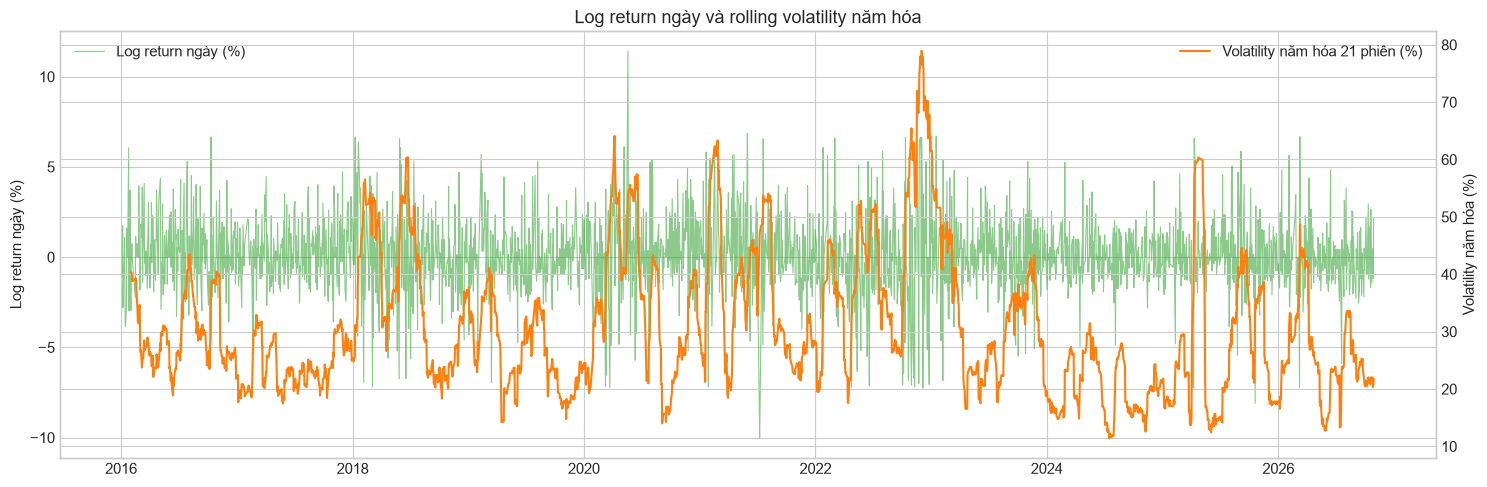

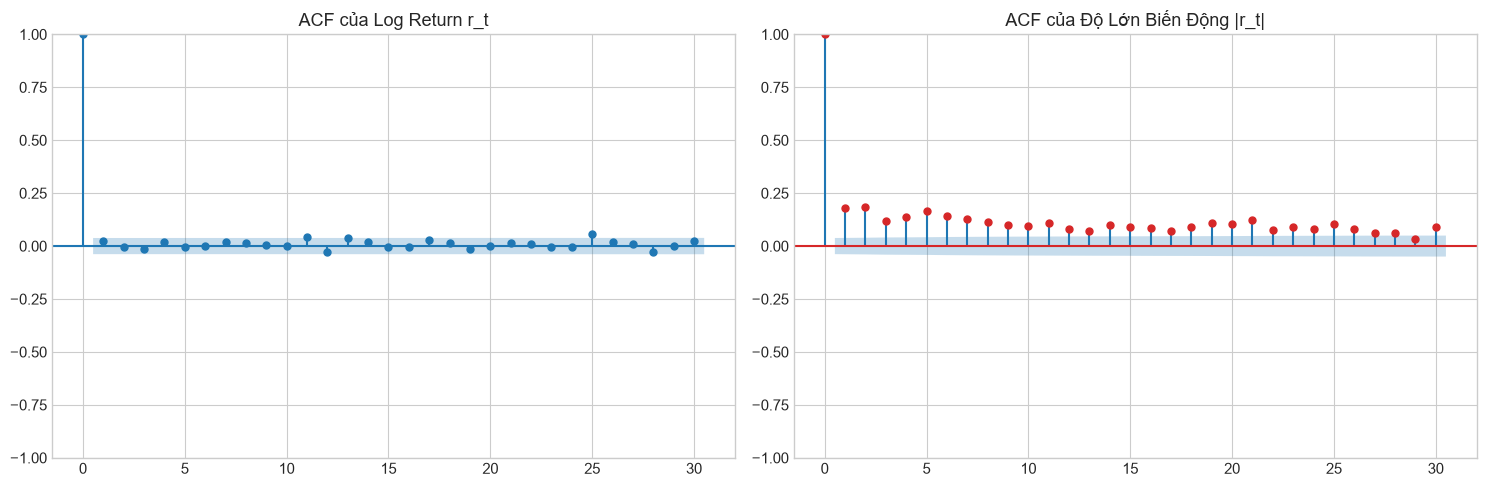

In [7]:
# Kiểm định Ljung-Box trên chuỗi lợi suất r_t
lb_ret = acorr_ljungbox(ret, lags=[5, 10, 20], return_df=True)
# Kiểm định Ljung-Box trên chuỗi độ lớn biến động |r_t|
lb_abs_ret = acorr_ljungbox(ret.abs(), lags=[5, 10, 20], return_df=True)

lb_comparison = pd.DataFrame({
    "Lags": [5, 10, 20],
    "p-value trên r_t (Lợi suất)": [f"{p:.4f}" for p in lb_ret["lb_pvalue"]],
    "Kết luận r_t": ["Bác bỏ H0" if p < 0.05 else "Chưa đủ bằng chứng bác bỏ H0" for p in lb_ret["lb_pvalue"]],
    "p-value trên |r_t| (Độ lớn biến động)": [f"{p:.4e}" for p in lb_abs_ret["lb_pvalue"]],
    "Kết luận |r_t|": ["Bác bỏ H0" if p < 0.05 else "Chưa đủ bằng chứng bác bỏ H0" for p in lb_abs_ret["lb_pvalue"]]
})

display(lb_comparison)

# 1. Vẽ đồ thị chuỗi thời gian Log Return & Dải biến động lăn 21 phiên (1 tháng)
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.index, df["log_return"] * 100, color="#2ca02c", alpha=0.55, linewidth=0.8, label="Log return ngày (%)")
rolling_vol = df["log_return"].rolling(window=21).std() * np.sqrt(trading_days) * 100
ax2 = ax.twinx()
ax2.plot(df.index, rolling_vol, color="#ff7f0e", linewidth=1.5, label="Volatility năm hóa 21 phiên (%)")
ax.set_ylabel("Log return ngày (%)")
ax2.set_ylabel("Volatility năm hóa (%)")
ax.set_title("Log return ngày và rolling volatility năm hóa")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout(); fig.savefig(figures_dir / "notebook_01_returns_and_volatility.png", dpi=150, bbox_inches="tight"); plt.show()

# 2. Vẽ biểu đồ Tự tương quan ACF (Autocorrelation Function)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_acf(df["log_return"], lags=30, ax=axes[0], color="#1f77b4", title="ACF của Log Return r_t")
plot_acf(df["log_return"].abs(), lags=30, ax=axes[1], color="#d62728", title="ACF của Độ Lớn Biến Động |r_t|")
plt.tight_layout()
fig.savefig(figures_dir / "notebook_01_acf.png", dpi=150, bbox_inches="tight")
plt.show()

---
## ⚖️ Bước 7: Phân tích [FACT 4] - Vi Cấu Trúc Sàn HOSE & Tỷ Lệ Nhãn ($RQ1$ vs $RQ2$)

Ngưỡng `limit_hit_threshold` được áp dụng cho simple return close-to-close trong parquet như **near-limit return proxy**. Giá điều chỉnh không đủ để xác định phiên thực sự chạm trần/sàn: cần giá giao dịch chưa điều chỉnh, giá tham chiếu lịch sử và quy tắc liên quan. Proxy cũng không xác định trắng mua/bán hay thanh khoản.

Ngưỡng nhãn RQ2 lấy từ config; tổng phí thành phần được kiểm tra ở Bước 2 với slippage mỗi chiều. Nhãn vượt ngưỡng là thống kê trên log return chứ không phải giao dịch lãi ròng. Các tỷ lệ dùng cùng mẫu có nhãn tương lai.

Near-limit return proxy: tăng >= 6.70%: 19; giảm <= -6.70%: 21; tổng: 40 phiên.
RQ1 direction = 1: 46.95%; direction = 0 (giảm hoặc không đổi): 53.05%
RQ2 return vượt ngưỡng proxy 0.45%: 38.07%
Đây là tỷ lệ nhãn quan sát, không phải xác suất giao dịch có lãi ròng.


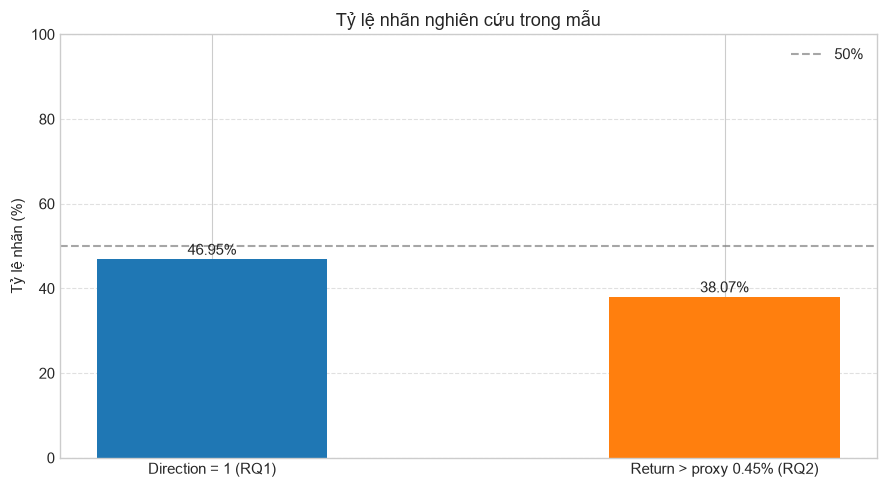

In [8]:
limit_threshold = config["market_microstructure"]["limit_hit_threshold"]
near_up = (df["simple_return"] >= limit_threshold).sum()
near_down = (df["simple_return"] <= -limit_threshold).sum()
up_ratio = df["target_direction"].mean() * 100
proxy_ratio = df["target_return_above_cost_proxy"].mean() * 100
print(f"Near-limit return proxy: tăng >= {limit_threshold:.2%}: {near_up}; giảm <= -{limit_threshold:.2%}: {near_down}; tổng: {near_up + near_down} phiên.")
print(f"RQ1 direction = 1: {up_ratio:.2f}%; direction = 0 (giảm hoặc không đổi): {100-up_ratio:.2f}%")
print(f"RQ2 return vượt ngưỡng proxy {round_trip_cost:.2%}: {proxy_ratio:.2f}%")
print("Đây là tỷ lệ nhãn quan sát, không phải xác suất giao dịch có lãi ròng.")
plt.figure(figsize=(9, 5))
categories = ["Direction = 1 (RQ1)", f"Return > proxy {round_trip_cost:.2%} (RQ2)"]
bars = plt.bar(categories, [up_ratio, proxy_ratio], color=["#1f77b4", "#ff7f0e"], width=0.45)
plt.axhline(50, color="gray", linestyle="--", alpha=0.7, label="50%")
plt.ylabel("Tỷ lệ nhãn (%)")
plt.title("Tỷ lệ nhãn nghiên cứu trong mẫu")
plt.ylim(0, 100)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f"{bar.get_height():.2f}%", ha="center")
plt.legend(); plt.grid(axis="y", linestyle="--", alpha=0.6); plt.tight_layout()
plt.savefig(figures_dir / "notebook_01_label_rates.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 🏆 BÀI HỌC RÚT RA TỪ NGÀY 1 & CHUẨN BỊ CHO NGÀY 2

1. ADF cung cấp bằng chứng theo mẫu và đặc tả, không bảo đảm tính dừng; kiểm tra đặc trưng và alignment theo thời gian ở Ngày 2.
2. Jarque-Bera và moments mô tả phân phối mẫu; quản trị rủi ro cần đánh giá thêm VaR/Expected Shortfall và điều kiện áp dụng.
3. Phụ thuộc của độ lớn return có thể hỗ trợ nghiên cứu biến động, không tự chứng minh long-memory, dự báo hướng hay alpha.
4. Tỷ lệ RQ2 là tỷ lệ nhãn log return vượt ngưỡng proxy cấu hình, không phải xác suất lãi ròng. Cần xác nhận 0.45% so với 0.50% theo các thành phần trước khi định nghĩa chi phí giao dịch.
5. `prob_threshold_long: 0.53` chỉ là cấu hình ban đầu, chưa tối ưu hay kiểm chứng. Đánh giá/chọn ngưỡng trên validation theo thứ tự thời gian; không tối ưu bằng test set. Cần định nghĩa execution, settlement, holding period và kiểm tra nguồn giá/corporate actions trước backtest.